# Does it generalize?
These are the archived hit counts from all 20 reserved seeds, 101–120. Each condition receives the same 100 test serves within a seed. “No recurrence,” “shuffled recurrence,” and “misaligned reward” each train a new decoder. “Spikes removed” and “groups scrambled” perturb the inputs to the trained decoder only at evaluation. Resampled rewards are drawn from the preceding reward history, breaking feedback alignment.

The table is included in the notebook so the analysis runs offline. The last cell can regenerate these values from the simulation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Each entry after the seed is a hit count out of 100 test serves.
columns = ['Initial', 'Trained', 'Shuffled recurrence', 'No recurrence',
           'Misaligned reward', 'Spikes removed', 'Groups scrambled']
scores = np.array([
    [101, 25, 84, 79, 81, 22, 19, 36],
    [102, 21, 90, 84, 86, 26, 23, 43],
    [103, 18, 71, 72, 77, 26, 21, 13],
    [104, 28, 85, 88, 81, 27, 28, 61],
    [105, 27, 90, 88, 92, 27, 26, 40],
    [106, 17, 95, 95, 96, 24, 17, 32],
    [107, 27, 91, 85, 87, 32, 29, 23],
    [108, 29, 88, 86, 88, 29, 37, 45],
    [109, 22, 79, 82, 84, 21, 19, 43],
    [110, 26, 82, 89, 87, 28, 32, 47],
    [111, 18, 87, 85, 86, 25, 16, 47],
    [112, 25, 83, 83, 83, 24, 21, 25],
    [113, 23, 89, 86, 87, 29, 19, 27],
    [114, 29, 81, 82, 89, 29, 32, 25],
    [115, 21, 86, 86, 79, 15, 22, 20],
    [116, 23, 88, 80, 88, 19, 17, 48],
    [117, 28, 89, 92, 88, 22, 27, 41],
    [118, 32, 85, 84, 86, 30, 32, 17],
    [119, 25, 78, 72, 77, 32, 27, 40],
    [120, 24, 83, 76, 82, 24, 23, 30],
])
seeds, hits = scores[:, 0], scores[:, 1:]
for label, mean in zip(columns, hits.mean(axis=0)):
    print(f'{label:<23} {mean:6.2f}%')

Initial                  24.40%
Trained                  85.20%
Shuffled recurrence      83.70%
No recurrence            85.20%
Misaligned reward        25.55%
Spikes removed           24.35%
Groups scrambled         35.15%


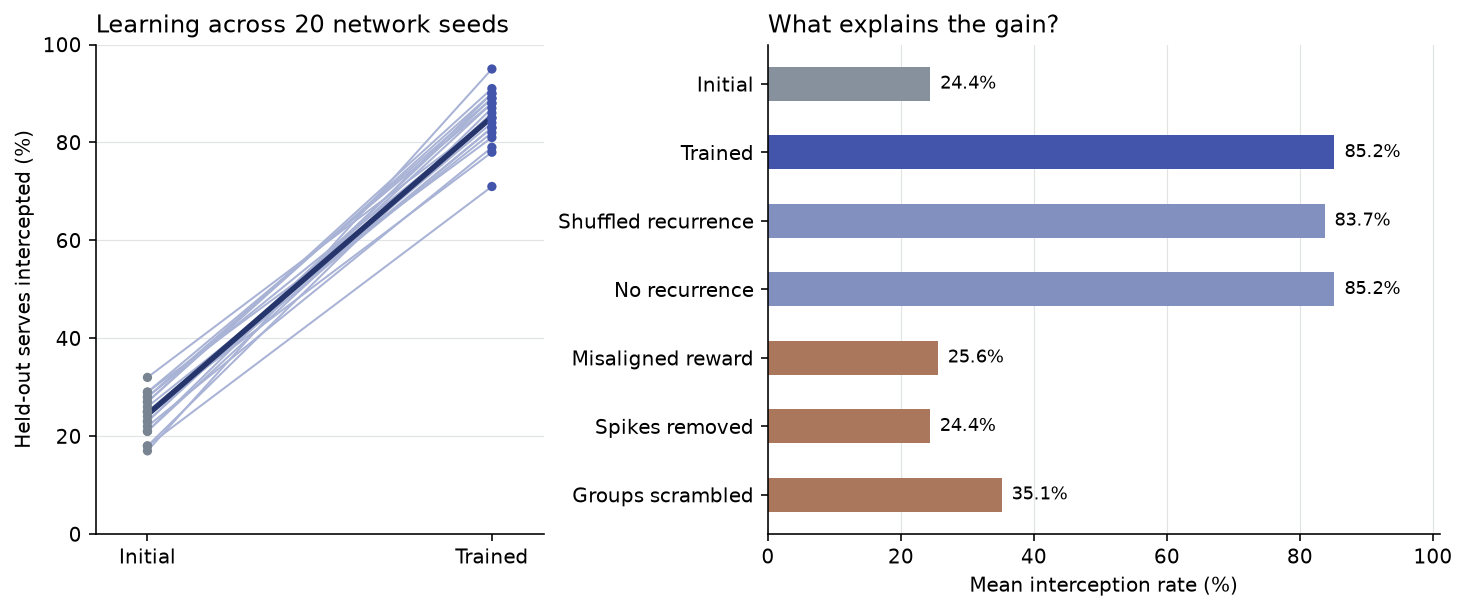

In [2]:
fig, (paired, controls) = plt.subplots(1, 2, figsize=(10, 4.1), layout='constrained',
                                       dpi=145, gridspec_kw={'width_ratios': [1, 1.5]})
for initial, trained in hits[:, :2]:
    paired.plot([0, 1], [initial, trained], color='#a9b3d6', linewidth=1)
    paired.scatter([0, 1], [initial, trained], s=13, color=['#788491', '#4355ab'], zorder=3)
paired.plot([0, 1], hits[:, :2].mean(axis=0), color='#26366d', linewidth=2.7)
paired.set(xticks=[0, 1], xticklabels=['Initial', 'Trained'], xlim=(-0.15, 1.15),
           ylim=(0, 100), ylabel='Held-out serves intercepted (%)')
paired.set_title('Learning across 20 network seeds', loc='left', fontsize=12)
means = hits.mean(axis=0)
y = np.arange(len(columns))
controls.barh(y, means, height=0.5, color=['#86919d', '#4355ab', '#8190be', '#8190be',
                                          '#aa765c', '#aa765c', '#aa765c'])
for j, mean in enumerate(means):
    controls.text(mean + 1.5, j, f'{mean:.1f}%', va='center', fontsize=9)
controls.set(yticks=y, yticklabels=columns, xlim=(0, 101), xlabel='Mean interception rate (%)')
controls.invert_yaxis()
controls.set_title('What explains the gain?', loc='left', fontsize=12)
for ax in (paired, controls):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y' if ax is paired else 'x', color='#e2e3e4', linewidth=0.6)
    ax.set_axisbelow(True)
plt.show()

In [3]:
gain = hits[:, 1] - hits[:, 0]
rng = np.random.default_rng(9001)
resamples = rng.choice(gain, size=(10_000, len(gain)), replace=True).mean(axis=1)
lo, hi = np.quantile(resamples, [0.025, 0.975])
print(f'Mean gain: {gain.mean():.1f} percentage points (paired 95% interval {lo:.2f} to {hi:.2f})')
print(f'Seeds with improvement: {(gain > 0).sum()} / {len(gain)}')

Mean gain: 60.8 percentage points (paired 95% interval 58.15 to 63.75)
Seeds with improvement: 20 / 20


The trained decoder reached 85.2% with structured recurrence and 85.2% when retrained with recurrent transmission disabled. Providing only its learned biases at evaluation brought the score back to 24.35%. The experiments support learned use of position-dependent spike patterns on this interception task. The bootstrap resamples whole network seeds.

### Optional reproduction from scratch
Set `rerun_seeds` to `[101]` to check one row, or `range(101, 121)` to run the full benchmark. Each seed trains four policies and evaluates them on matched serves. The default uses the archived counts above.

In [4]:
from model import LearningConfig, run_learning

rerun_seeds = []
for seed in rerun_seeds:
    config = LearningConfig()
    base = run_learning(config, seed, topology='structured')
    shuffled = run_learning(config, seed, topology='shuffled')
    absent = run_learning(config, seed, topology='none')
    resampled = run_learning(config, seed, reward_mode='resampled_reward')
    conditions = [base['before'], base['after'], shuffled['after'], absent['after'], resampled['after'],
                  base['ablations']['zero_spikes'], base['ablations']['scrambled_spikes']]
    actual = [round(c['success_fraction'] * config.eval_trials) for c in conditions]
    expected = hits[np.flatnonzero(seeds == seed)[0]]
    np.testing.assert_array_equal(actual, expected)
    print(f'Seed {seed}: reproduced all seven hit counts')